# Task 2: Customer Segmentation with K-Means

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data cleaning and Exploration

In [3]:
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
display(df.head())
df.info()
df.describe()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].apply(pd.to_numeric, errors="coerce")

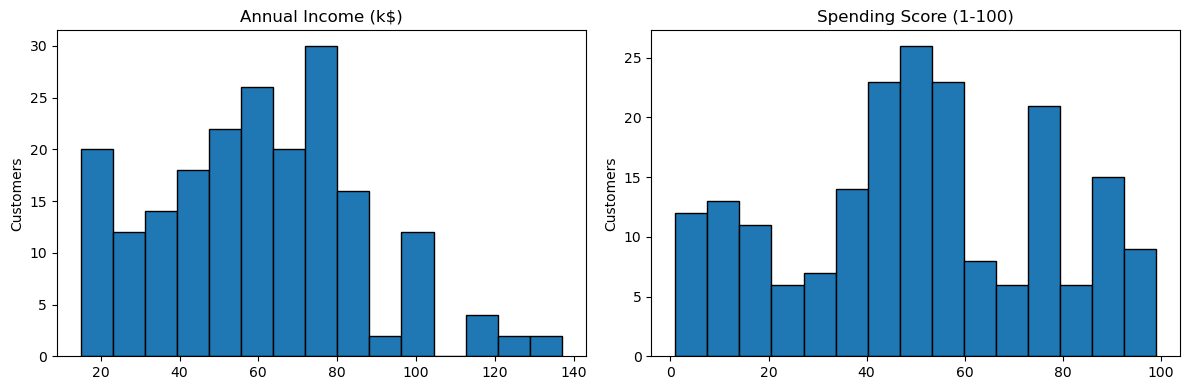

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, features):
    ax.hist(X[col], bins=15, edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("Customers")
plt.tight_layout(); plt.show()

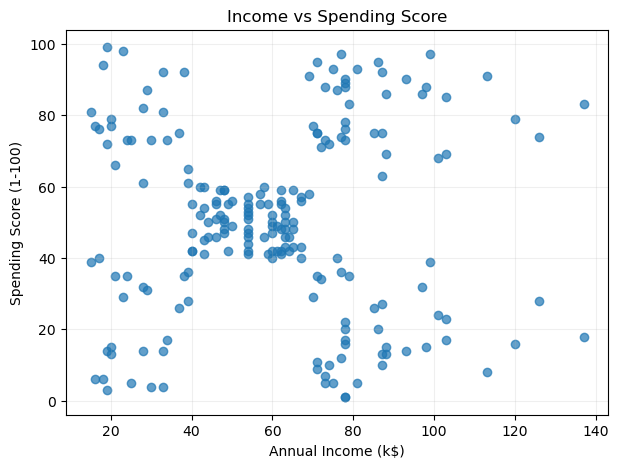

In [6]:
plt.figure(figsize=(7,5))
plt.scatter(X[features[0]], X[features[1]], alpha=.7)
plt.xlabel(features[0]); plt.ylabel(features[1]); plt.title("Income vs Spending Score")
plt.grid(alpha=.2); plt.show()

## Scaling the features

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled matrix:", X_scaled.shape)

Scaled matrix: (200, 2)


## Selecting the number of clusters using Elbow and Silhouette methods

In [8]:
k_values = list(range(2, min(11, len(X))))
inertias, silhouettes = [], []

In [9]:
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

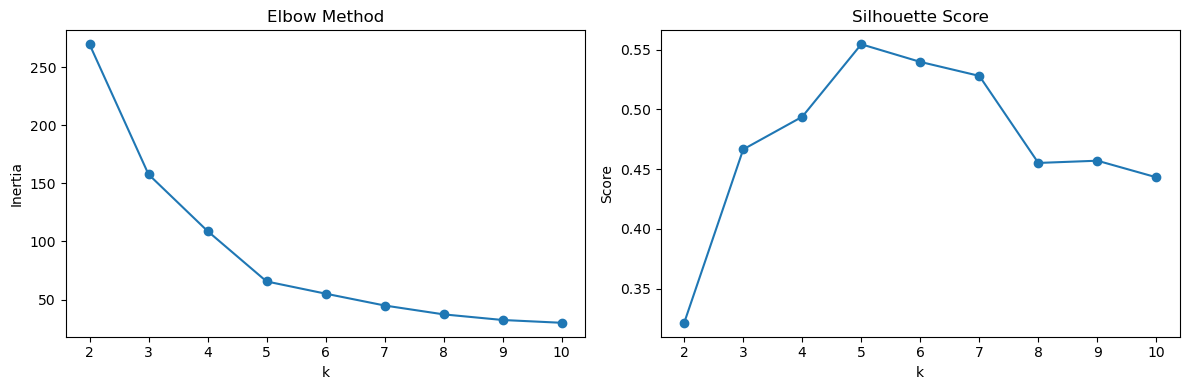

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(k_values, inertias, marker="o"); axes[0].set(title="Elbow Method", xlabel="k", ylabel="Inertia")
axes[1].plot(k_values, silhouettes, marker="o"); axes[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
plt.tight_layout(); plt.show()

## Training K-Means and assigning cluster labels

In [11]:
best_k = k_values[int(np.argmax(silhouettes))]
print("number of clusters:", best_k)

number of clusters: 5


In [12]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

In [13]:
results = df.loc[X.index].copy()
results["Cluster"] = labels
print("Silhouette score:", round(silhouette_score(X_scaled, labels), 3))
display(results.head())

Silhouette score: 0.555


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


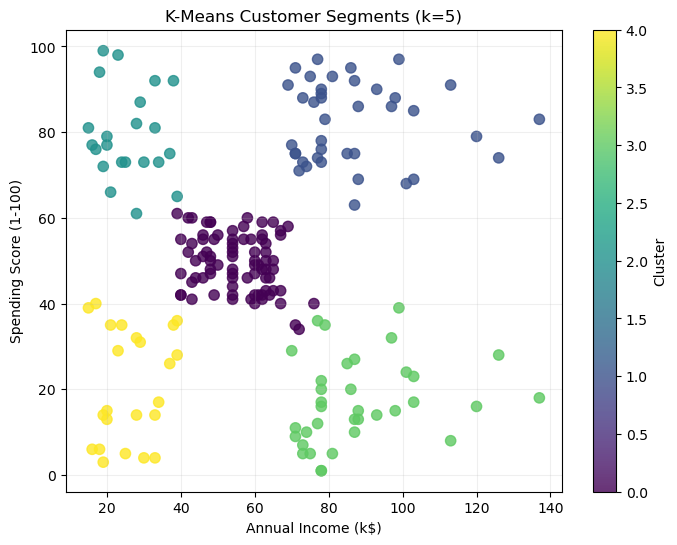

In [14]:
plt.figure(figsize=(8,6))
scatter = plt.scatter(X[features[0]], X[features[1]], c=labels, cmap="viridis", s=55, alpha=.8)
plt.xlabel(features[0]); plt.ylabel(features[1]); plt.title(f"K-Means Customer Segments (k={best_k})")
plt.colorbar(scatter, label="Cluster"); plt.grid(alpha=.2); plt.show()

## Interpret cluster profiles

In [15]:
profile = results.groupby("Cluster").agg(
    customers=("Cluster", "size"),
    average_income=(features[0], "mean"),
    average_spending_score=(features[1], "mean")
).round(2)
display(profile)

,customers,average_income,average_spending_score
Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


## DBSCAN comparison

In [16]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
results["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)
display(results["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64

In [17]:
results.to_csv("customer_segments.csv", index=False)
profile.to_csv("customer_cluster_profile.csv")
print("Saved customer_segments.csv and customer_cluster_profile.csv")

Saved customer_segments.csv and customer_cluster_profile.csv


##  Conclusion
The selected number of clusters is 5

Silhouette score is 0.555

The income/spending characteristics of each group:
High income: cluster 1 and 3, Low income: cluster 2 and 4, High spending: cluster 1 and 2, Low spending: cluster 3 and 4

Retailer could use these segments to know the best marketing strategy (what to sell,what price to offer and how to talk to them)